# A demo for the whole pipeline: a language model learns to propose operator bases

## 0. Background and settings

The `src` contains codes that build an effective stochastic dynamics in a coarse grained grid for a PDE in a fine grid. The effective stochastic dynamics is obtained via Mori-Zwanzig formalism and the dynamical equation for a state vector involves a linear combinations of operators in a basis, where the coefficients are called kernels and are inferred from data. 

Here, we propose that one can use **a language model to choose a good basis that best explains the data**. The language model that does the job is post-trained via the following schema

```
        data ──> diagnostics ──┐
                               v
    ┌──────────────>  language model  ── proposes ──> operator basis
    │                          ^                            │
    │                          │                   Mori kernels at every scale,
    │                          │                   RG flow, effective dynamics 
    │                          │                            │
    │                          └── RG-flow feedback <───────┤ which operators matter at coarse scales
    │                                                       │
    └── GRPO post-training, every few rounds <── reward ────┘ accurate and fast at the coarsest scale
```

To explain the whole pipeline, we devide this notebook into the following sections: 
1. **The tasks** (`posttrain.tasks`): a family of dataset simulated from some 1D PDEs. The model will be asked to generate operator bases that best explain the data.
2. **Injecting the data** (`posttrain.prompts`): what the model reads about a dataset. The model sees some statistics about datasets but never the corresponding PDEs.
3. **The reward** (`posttrain.reward`): the reward used for post-training.
4. **The RG-flow feedback** (`posttrain.feedback`): what the model is told after each proposal. The feedback reflects the Renormalization Group flows of the kernels for a proposed operator basis, extrapolated to the coarse grid.
5. **Searching without a model** (`posttrain.search`): the basis found by a different method, greedy forward selection, in a pool. It can be viewed as the yardstick for the model.
6. **The loop** (`posttrain.loop`, `posttrain.policy`): as in the above diagram.
7. **Did it learn?** The advantage over greedy method before and after each update, on training tasks and on unseen tasks.
8. **The final bases**: the basis proposed by the language model after trainning.
9. **The effective dynamics** (`models.mz_noise`): Mori-Zwanzig formalism at the coarse grained grid. It constains kernels for the drift and memory terms and a **stochastic RNN** for the noise term.

Sections 1-5 run on any laptop in a few minutes. Sections 6-9 need the language model. Install it with
`uv sync --group posttrain`; it is downloaded from the Hugging Face hub on first use. 

Now import all of the functions.

In [14]:
import os
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "1.0"
os.environ["PYTORCH_MPS_LOW_WATERMARK_RATIO"] = "0.8"

import sys

sys.path.append("../src")

import json
from pathlib import Path

import numpy as np

from models.mz_noise import evaluate, fit_rnn_noise, simulate, spectrum
from posttrain.loop import (DiscoveryLoop, LoopConfig, attempt, final_bases, learning_curves, greedy_yardstick, session_messages)
from posttrain.reward import score
from posttrain.tasks import TASKS, environment, task
import matplotlib.pyplot as plt

INK, MUTED, GRID = "#0b0b0b", "#8a8984", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 2, "lines.markersize": 8, "legend.frameon": False,
})

**Settings.** `MODEL` is any chat model from the Hugging Face hub, or a local directory. `CONFIG` sets for the loop in Section 6. Each **round** runs one session on every training task, with `tasks_per_round` tasks randomly selected from a pool of tasks each round. In a session the model proposes up to `max_turns` turns until its best basis passes the check of `posttrain.verify` (Section 8). Each proposal is made after the feedback on the previous one, with `group` sampled replies from the model per proposal. The model is post-trained every `update_every` rounds. `hints` sets what the first prompt shows besides the statistics of the data (Section 2), and `candidates` how many operators the feedback lists after each proposal. `RESUME` is an option to decide whether a post-training continues from the previous unfinished one. 

In [ ]:
MODEL = "Qwen/Qwen2.5-Math-7B"
OUTPUT = Path("../runs/notebook")
CONFIG = LoopConfig(rounds=40, max_turns=3, group=6, update_every=1, eval_every=4, tasks_per_round=4, max_hours=None, hints="stats", candidates=0, output_dir=str(OUTPUT))
RESUME = False

## 1. The tasks

Twenty-four PDEs $\partial_t u = F(u)$ on a periodic domain, all with random initial states. Among then, seventeen are for training, where the model will be asked to propose basis that explains the data and update its parameters based on the quality of the proposal, and seven are **unseen**, which will be used to test whether the model learns to read the data while proposing basis rather than memorizes answers for the training tasks. Each task has 128 grid points, 21 snapshots, 100 **fit trajectories**, on which the kernels are fitted, and 50 **scoring trajectories**, on which the effective dynamics's prediction error on the coarse grained grid is measured. 

In [16]:
for t in TASKS:
    print(f"{t.split:6s}  {t.name:22s}  du/dt = {t.rhs}")
envs = {t.name: environment(t) for t in TASKS}

train   burgers                 du/dt = -0.5*D(u**2) + 0.08*D(u,2)
train   burgers_weak            du/dt = -0.25*D(u**2) + 0.08*D(u,2)
train   burgers_viscous         du/dt = -0.5*D(u**2) + 0.16*D(u,2)
train   modified_burgers        du/dt = -D(u**3)/3 + 0.08*D(u,2)
train   modified_strong         du/dt = -D(u**3) + 0.08*D(u,2)
train   modified_thin           du/dt = -D(u**3)/3 + 0.04*D(u,2)
train   burgers_cubic           du/dt = -0.5*D(u**2) - 0.3*D(u**3) + 0.08*D(u,2)
train   burgers_cubic_viscous   du/dt = -0.5*D(u**2) - 0.3*D(u**3) + 0.16*D(u,2)
train   cubic_dominant          du/dt = -0.2*D(u**2) - 0.8*D(u**3) + 0.08*D(u,2)
train   cubic_dominant_viscous  du/dt = -0.2*D(u**2) - 0.6*D(u**3) + 0.16*D(u,2)
train   cubic_strong            du/dt = -0.3*D(u**2) - 1.0*D(u**3) + 0.08*D(u,2)
train   kpz                     du/dt = -0.5*D(u)**2 + 0.08*D(u,2)
train   kpz_strong              du/dt = -D(u)**2 + 0.08*D(u,2)
train   kpz_burgers             du/dt = -0.2*D(u**2) - 0.5*D(u)**2 + 0

## 2. Injecting the data into the language model

The first prompt that the model sees. It consists of a fixed **system prompt** and the **diagnostics** of one dataset, which are the numbers an analyst measures before
fitting anything. 

In [17]:
first_turn = session_messages(task("burgers"), history=[], hints=CONFIG.hints, listed=CONFIG.candidates > 0)
print(first_turn[0]["content"])  # the system prompt
print("\n" + "─" * 100 + "\n")
print(first_turn[-1]["content"])

You propose operator bases for the effective dynamics of a coarse-grained field.

Data: trajectories of a real scalar field u(x, t) on a periodic domain, from an unknown deterministic evolution law
with random initial states, observed at equally spaced times and coarse-grained at several scales.

Model. A basis {O_1, ..., O_p} defines the observables g = (u, O_1(u), ..., O_p(u)); u is always included. At each
scale, every Fourier mode of the observables follows a Mori-Zwanzig equation with memory,
    g_k(t+1) = sum_l Omega^(l)(k) g_k(t-l) + noise,
whose kernels are fitted from correlations. The kernels flow with the scale; they are extrapolated to a coarser scale
and the effective dynamics simulates u there, re-evaluating the operators on the simulated u at every step.

A basis is good if its effective dynamics is accurate and fast: accurate when the operators carry the nonlinearities that u
needs to predict its own future, fast when there are few operators and they are cheap (each on

## 3. The reward

Once the model has generated a reply. It will be processed first (`posttrain.reward.read_basis`). Each line that is not a well-defined operator is removed from the basis at a penalty, and so is each operator whose addition would make one prediction step of the effective dynamics more than 50 times as expensive as a step with $u$ alone, and each line beyond the 8th operator. Each operator that repeats an observable already in the basis ($u$ itself, an operator linear in $u$, an $x$-derivative of another operator) is removed at a penalty too. Only then is the basis scored on the task's environment (`posttrain.reward.score`). The reward has three parts:

* **accuracy** $= -\log(\text{error})$: the relative error of the effective dynamics at the prediction scale (block size 16) on the task's scoring trajectories, with kernels fitted at block sizes 2, 4, 8 and extrapolated along the RG flow;
* **speed** $= -0.1 \log(\text{cost})$: the floating-point cost of one step of the effective dynamics relative to $u$ alone. 
* **format**: a penalty of 0.5 per ignored line and per repeated operator, and of 1.0 without a `<basis>` block. In the discovery loop (Section 6), proposing a basis already tried in the session costs another 0.5.

The following codes compute the rewards for a set of examples for the task named "burgers". 

In [18]:
replies = {
    "u alone": "<basis></basis>",
    "u²": "<basis>u**2</basis>",
    "u², u_x², u³": "<basis>u**2\nD(u)**2\nu**3</basis>",
    "a typo": "<basis>u**2\nu^3</basis>",
    "a repeat": "<basis>u**2\nu*D(u)</basis>",
    "too costly": "<basis>u**2\n(u + D(u) + D(u,2) + D(u,3))**8</basis>",
    "no basis block": "I think u**2 matters.",
}
print(f"{'reply':18s} {'error':>7s} {'cost':>6s} {'accuracy':>9s} {'speed':>7s} {'format':>7s} {'total':>7s}")
for name, reply in replies.items():
    s = score("burgers", reply)
    print(f"{name:18s} {s.error:7.4f} {s.relative_cost:6.2f} {s.accuracy:9.3f} {s.speed:7.3f} "
          f"{s.format:7.2f} {s.total:7.3f}")

reply                error   cost  accuracy   speed  format   total
u alone             0.2320   1.00     1.461  -0.000   -0.00   1.461
u²                  0.1654   4.05     1.799  -0.140   -0.00   1.660
u², u_x², u³        0.1656  11.01     1.798  -0.240   -0.00   1.559
a typo              0.1654   4.05     1.799  -0.140   -0.50   1.160
a repeat            0.1654   4.05     1.799  -0.140   -0.50   1.160
too costly          0.1654   4.05     1.799  -0.140   -0.50   1.160
no basis block      2.0000   1.00    -0.693   0.000   -1.00  -1.693


from the list above, one can clearly see that $u^2$, which appears on the right hand side of the Burgers equation, has the highest reward. 

## 4. The RG-flow feedback

Here is the second-turn prompt after a first proposal of $\{u^2, u_x^2, u^3\}$ on Burgers: the same system prompt, the same diagnostics, followed by the feedback.

The feedback summarizes the RG flow of the proposed basis (`posttrain.feedback.flow_report`):

In [19]:
first = attempt(task("burgers"), replies["u², u_x², u³"], CONFIG)
second_turn = session_messages(task("burgers"), history=[first], hints=CONFIG.hints, listed=CONFIG.candidates > 0)
print(second_turn[-1]["content"].split("\n\n", 1)[1])  # everything after the diagnostics

Bases you have tried, best first:
- [u, u**2, D(u)**2, u**3]: error 0.1656, cost x11.01, reward +1.559

RG flow of your best basis:
Basis [u, u**2, D(u)**2, u**3]: error 0.1656 at block size 16 (the prediction scale) with the extrapolated kernels (0.1418 with kernels fitted there), cost x11.01 of u alone, reward +1.559.
  unexplained step of u: 0.100 (block size 2), 0.053 (block size 4), 0.128 (block size 8)
  RG flow of the share of the step of u each operator carries (block size 2 -> block size 4 -> block size 8 -> block size 16, the last one extrapolated):
    u**2: 0.741 -> 0.753 -> 0.679 -> 0.471 (shrinks); without it the error is x1.57
    D(u)**2: 0.088 -> 0.098 -> 0.081 -> 0.004 (shrinks); without it the error is x1.01
    u**3: 0.143 -> 0.161 -> 0.232 -> 0.079 (shrinks); without it the error is x0.99
  important at block size 16: u**2
  negligible at block size 16 (dropping one changes the error by less than 2% and makes the effective dynamics cheaper): D(u)**2, u**3

Propose 

In the above example, the feedback we designed identifies $u^2$ as the most important operator: the error at block size 16 is 57% larger without it, while $u_x^2$ and $u^3$
are less important. A model that reads this is expected to drop them in its next proposal and **the post-training process is implemented to make sure that the model is rewarded to make that move.**

## 5. Searching without a model: greedy forward selection

There is an alternative way to search for a basis with the best reward without using a language model, which we call greedy forward selection. The idea is to start from $u$ alone, at each step add the operator from the pool that raises the reward most, among the few most relevant ones, and stop when no addition raises it. This methods provide a yardstick for what is considered to be a good basis in the pool for the reward function that we choose. Here, we set the pool to be the set of all monomial basis with powers at most 3 and derivatives at most 4. The greedy method will search for monomials in this pool. 

In [7]:
yardsticks = {t.name: greedy_yardstick(t, CONFIG) for t in TASKS}
print(f"{'task':17s} {'greedy basis':28s} {'error':>7s} {'cost':>6s} {'reward':>7s}")
for name, s in yardsticks.items():
    print(f"{name:17s} {str(['u', *s.names]):28s} {s.error:7.4f} {s.relative_cost:6.2f} "
          f"{s.accuracy + s.speed:7.3f}")

task              greedy basis                   error   cost  reward
burgers           ['u', 'u^2']                  0.1654   4.05   1.660
burgers_weak      ['u', 'u^2']                  0.0937   4.05   2.228
burgers_viscous   ['u', 'u^2']                  0.1014   4.05   2.149
modified_burgers  ['u', 'u^3']                  0.0977   4.09   2.186
modified_strong   ['u', 'u^3']                  0.1437   4.09   1.799
modified_thin     ['u']                         0.1429   1.00   1.946
burgers_cubic     ['u', 'u^2', 'u^3']           0.1424   7.14   1.753
burgers_cubic_viscous ['u', 'u^2', 'u^3']           0.0939   7.14   2.169
cubic_dominant    ['u', 'u^2', 'u^3']           0.1342   7.14   1.812
cubic_dominant_viscous ['u', 'u^2', 'u^3']           0.0772   7.14   2.365
cubic_strong      ['u', 'u^2', 'u^3']           0.1404   7.14   1.767
kpz               ['u']                         0.1192   1.00   2.127
kpz_strong        ['u']                         0.0914   1.00   2.392
kpz_burgers

The best greedy bases differ from task to task, as the nonlinearity of PDEs differ from task to task. 

As the pool contains all types of nonlinearity of PDE tasks, the greedy method searches among all of the operators relevant to PDEs, and hence, it reflects a baseline of good basis for the reward function of our choice. One important observation is that, given our reward function, the greedy bases do not always coincide with the basis on the right hand side of the PDEs in Section 1. 

*I have a good idea on how to design the reward function. To be implemented later.*

## 6. The loop

Now start the training. First, what does the model propose **before any post-training**? The following code gives the first round of replies when RESUME=False. 

In [ ]:
from posttrain.loop import resume_point
from posttrain.policy import HFPolicy, UpdateConfig

point = resume_point(OUTPUT) if RESUME else None  # (round, checkpoint) of the last update
policy = HFPolicy.from_pretrained(MODEL, adapter=None if point is None else str(point[1]), lora_rank=16, max_new_tokens=384, config=UpdateConfig(learning_rate=5e-5, epochs=2, micro_batch=4, forward_batch=1, gradient_checkpointing=True, beta=0.1))
print(f"{MODEL} on {policy.device}" + ("" if point is None else f", resumed from {point[1]}"))

reply = policy.generate(first_turn, 1, greedy=True)[0].text
print(reply)
print("\n" + "─" * 100 + "\n")
print(attempt(task("burgers"), reply, CONFIG).report.text())

/Users/miao/Documents/GitHub/data-driven-eft/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1109 23:35:11.914000 89257 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 338/338 [00:05<00:00, 60.32it/s]


Qwen/Qwen2.5-1.5B-Instruct on mps:0
<basis>
2*u*D(u,2) - D(u)**3
</basis>

────────────────────────────────────────────────────────────────────────────────────────────────────

Basis [u, 2*u*D(u,2) - D(u)**3]: error 0.2307 at block size 16 (the prediction scale) with the extrapolated kernels (0.2203 with kernels fitted there), cost x5.83 of u alone, reward +1.290.
  unexplained step of u: 0.816 (block size 2), 0.805 (block size 4), 0.700 (block size 8)
  RG flow of the share of the step of u each operator carries (block size 2 -> block size 4 -> block size 8 -> block size 16, the last one extrapolated):
    2*u*D(u,2) - D(u)**3: 0.117 -> 0.137 -> 0.145 -> 0.039 (shrinks); without it the error is x1.01
  negligible at block size 16 (dropping one changes the error by less than 2% and makes the effective dynamics cheaper): 2*u*D(u,2) - D(u)**3


Now the loop (`DiscoveryLoop.run`). 

The log shows, for every evaluation, that is one time every `eval_every` rounds, whether each session is passed and how many turns the model takes to pass. The first and best proposed basis with their **advantage over greedy** basis in one session are also reported. The advantage is the difference between the rewards of the two basis. Note that the evaluation is carried out on all of the tasks. 

In [ ]:
loop = DiscoveryLoop(policy, CONFIG)
loop.yardsticks = yardsticks  # computed in Section 5
verifications = loop.run(resume=RESUME)

[eval] before post-training
  [eval train] burgers          not passed in 3 turns: it is not a local optimum: dropping, adding or swapping a single operator gives a better basis; a greedy search that adds one operator at a time, starting from u alone, finds a better basis
                                 first [u, 2*u*D(u,2) - D(u)**3]: error 0.2307, cost x5.83, reward +1.290 advantage over greedy -0.370
                                 best  [u, 2*u*D(u,2) - D(u)**3]: error 0.2307, cost x5.83, reward +1.290 advantage over greedy -0.370
  [eval train] burgers_weak     not passed in 3 turns: it is not a local optimum: dropping, adding or swapping a single operator gives a better basis; a greedy search that adds one operator at a time, starting from u alone, finds a better basis
                                 first [u, 2*u*D(u,2) - D(u)**3]: error 0.1334, cost x5.83, reward +1.838 advantage over greedy -0.389
                                 best  [u, 2*u*D(u,2) - D(u)**3]: error 0.133

[round 2] mean reward of the samples +0.394, best per task cubic_dominant +1.420, burgers_cubic_viscous +1.559, burgers_cubic +1.392, quadratic_source +2.142, 0/4 sessions passed the check, 1/12 groups with one reward for all replies (no signal) (405s)
[update after round 2] groups 12, completions 62, kl 0.01471, loss -0.01712, ratio 0.9621, clipped 0.1451, skipped 0, weight_change 1.873 (1041s)
[round 3] mean reward of the samples +1.296, best per task kpz +1.953, modified_thin +1.946, cubic_dominant_viscous +1.909, burgers_weak +2.019, 1/4 sessions passed the check, 0/11 groups with one reward for all replies (no signal) (205s)
[update after round 3] groups 11, completions 62, kl 0.05804, loss 0.02287, ratio 1.004, clipped 0.05059, skipped 0, weight_change 2.219 (925s)
[round 4] mean reward of the samples +1.148, best per task cubic_strong +1.501, kdv_strong +1.284, modified_burgers +2.049, kpz_viscous +2.297, 0/4 sessions passed the check, 1/12 groups with one reward for all replies

## 7. Did the model learn?

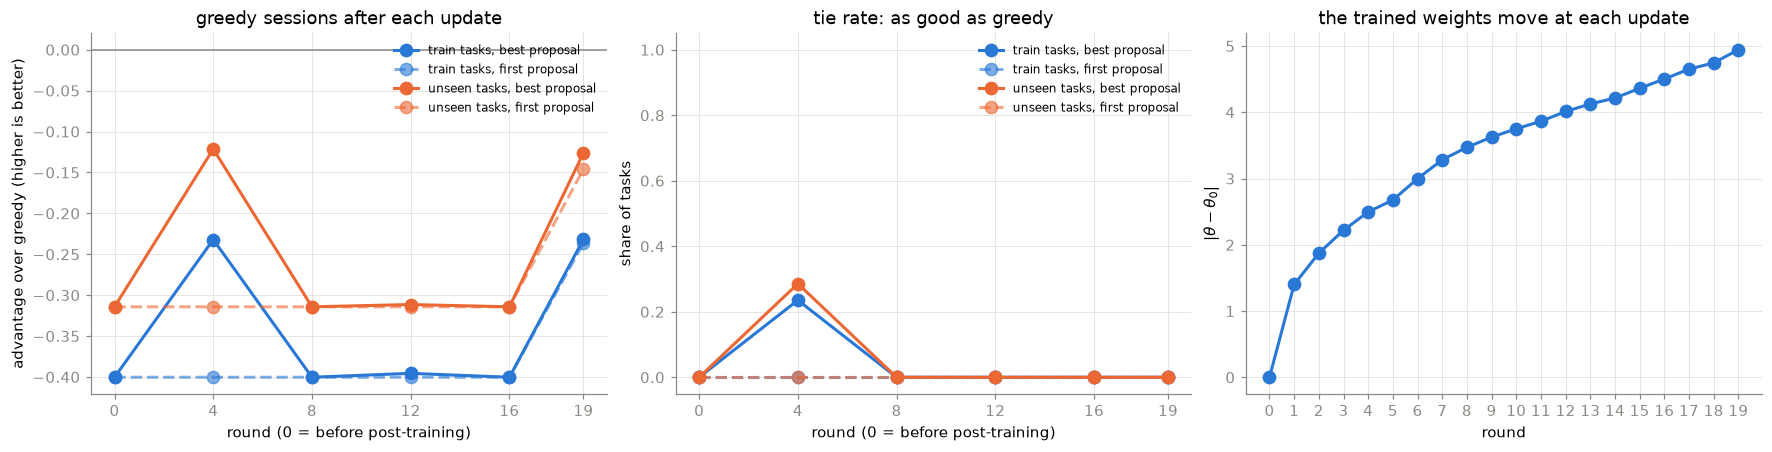

train  tasks at round 19: tie rate 0% (first proposal 0%), mean advantage over greedy -0.232
unseen tasks at round 19: tie rate 0% (first proposal 0%), mean advantage over greedy -0.126


In [ ]:
curves = learning_curves(loop.history)
# the tie rate: the share of tasks whose proposal is at least as good as greedy's basis (the same basis, or a better one)
evals = [h for h in loop.history if h["kind"] == "eval"]
tie_rate = lambda split, which: [np.mean([h[f"{which}_advantage"] >= -1e-6 for h in evals if h["split"] == split and h["round"] == r]) for r in curves[split]["round"]]
fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for color, split in zip(SERIES, ("train", "unseen")):
    c = curves[split]
    ax0.plot(c["round"], c["best_advantage"], "o-", color=color, label=f"{split} tasks, best proposal")
    ax0.plot(c["round"], c["first_advantage"], "o--", color=color, alpha=0.6, label=f"{split} tasks, first proposal")
    ax1.plot(c["round"], tie_rate(split, "best"), "o-", color=color, label=f"{split} tasks, best proposal")
    ax1.plot(c["round"], tie_rate(split, "first"), "o--", color=color, alpha=0.6, label=f"{split} tasks, first proposal")
ax0.axhline(0, color=MUTED, linewidth=1)
ax0.set_xticks(curves["train"]["round"])
ax0.set(xlabel="round (0 = before post-training)", ylabel="advantage over greedy (higher is better)",
        title="evaluation sessions after each update")
ax0.legend(fontsize=8)
ax1.set_xticks(curves["train"]["round"])
ax1.set(xlabel="round (0 = before post-training)", ylabel="share of tasks", ylim=(-0.05, 1.05),
        title="tie rate: as good as greedy")
ax1.legend(fontsize=8)
ax2.plot([0, *curves["updates"]["round"]], [0, *curves["updates"]["weight_change"]], "o-", color=SERIES[0])
ax2.set_xticks([0, *curves["updates"]["round"]])
ax2.set(xlabel="round", ylabel=r"$|\theta - \theta_0|$", title="the trained weights move at each update")
plt.show()
for split in ("train", "unseen"):
    c = curves[split]
    print(f"{split:6s} tasks at round {c['round'][-1]}: tie rate {tie_rate(split, 'best')[-1]:.0%} "
          f"(first proposal {tie_rate(split, 'first')[-1]:.0%}), "
          f"mean advantage over greedy {c['best_advantage'][-1]:+.3f}")

* Left: the mean advantage over greedy of the **evaluation sessions** after each round. The number changes every `eval_eval` rounds.

* Middle: the **tie rate**, the share of tasks where the proposal is at least as good as greedy's basis (an advantage of at least $-10^{-6}$).

* Right: how far the trained weights have moved, $|\theta - \theta_0|$.

Note that in this demo, greedy method behaves very well so we expect that a post trained model behaves similarly as the greedy method at best. In a more complicated dynamical systems, we may observe that a post trained model can actually beat the greedy method, so that the advantage will move from below zero to above zero through the training. 

## 8. The final bases

The best basis of the last evaluation session on every task, judged on a new ensemble (seed 200) that the model in the training loop has never seen. The reward and the RG-flow feedback are judged on ensemble (seed 0) in the training loop, and the verdict of the proposed basis at the end of sessions is judged on ensemble (seed 100). 

The check (`posttrain.verify`) asks whether there is a proposed basis, whether the proposed basis is a local optimum, whether it beats the greedy basis, and whether it beats the other known basis. In the training loop, we cache every basis proposed by the model and construct a pool of **known bases** from three sources:

* **pool for the greedy forward selection**
* **pool of a local neighbor of the final basis**: swap, delete, and add monomials are considered as local moves
* **a selection of bases met elsewhere in the training**: the top 5 that the training evaluated and the top 5 that the check at the end of sessions evaluated (seed 100)

The columns:

* **final_basis**: the operators of the basis, as the model wrote them.
* **error**: the relative error of the effective dynamics of $u$ at block size 16, with the kernels fitted at block sizes 2, 4, 8 and extrapolated along the RG flow.
* **cost**: the cost of one step of the effective dynamics with the basis, relative to $u$ alone, counted in FFTs.
* **final_check**: whether the basis passes the check.
* **local_gain**: how much the local search raises the reward.
* **vs_greedy**: whether the reward of the basis is at least that of the basis greedy forward selection.
* **rank**: the position of the basis among itself and the known bases, by reward.
* **Pareto_optimal**: whether no known basis improves the final basis in the error or cost. Unlike the rank, it does not depend on how the reward weighs accuracy against speed: a basis of rank 2 can be Pareto optimal when the one above it is cheaper but less accurate.
* **speedup**: the measured wall time of the direct simulation on the fine grid divided by that of the effective dynamics on the coarse grid.


In [27]:
bases = final_bases(OUTPUT)
rows = json.loads((OUTPUT / "verification.json").read_text())
basis_text = lambda row: "[" + ", ".join(["u", *row["operators"]]) + "]"
wt, wb = max(len(r["task"]) for r in rows), max(len(basis_text(r)) for r in rows)  # the widest task and basis
print(f"{'task':{wt}s}  {'final_basis':{wb}s}  {'error':>6s}  {'cost':>5s}  {'final_check':>11s}  {'local_gain':>10s}  "
      f"{'vs_greedy':>9s}  {'rank':>6s}  {'Pareto_optimal':>14s}  {'speedup':>7s}")
for row in rows:
    rank = f"{row['rank']}/{row['n_known'] + 1}"
    speedup = "none" if row["speedup"] is None else f"{row['speedup']:.0f}x"
    print(f"{row['task']:{wt}s}  {basis_text(row):{wb}s}  {row['error']:6.4f}  {row['relative_cost']:5.2f}  "
          f"{str(row['passed']):>11s}  {row['local_gain']:+10.3f}  {'beats' if row['beats_baseline'] else 'loses':>9s}  "
          f"{rank:>6s}  {str(row['pareto_optimal']):>14s}  {speedup:>7s}")

task                    final_basis                                                       error   cost  final_check  local_gain  vs_greedy    rank  Pareto_optimal  speedup
burgers                 [u, 2*u*D(u,1)]                                                  0.1882   4.87        False      +0.019      loses    2/19           False     193x
burgers_weak            [u, 2*u*D(u,1)]                                                  0.1086   4.87        False      +0.000      loses    2/22            True     190x
burgers_viscous         [u, 2*u*D(u,1)]                                                  0.1161   4.87        False      +0.019      loses    2/20            True     195x
modified_burgers        [u, 2*u*D(u,1) - D(u)*D(u,1) + u**2]                             0.1479   5.05        False      +0.348      loses   16/19           False     184x
modified_strong         [u, 2*u*D(u,1)]                                                  0.2226   4.87        False      +0.452      loses  

## 9. The effective dynamics on the final basis

With the final basis $\{O_1, \dots, O_p\}$, the observables are $g = (u, O_1(u), \dots, O_p(u))$. At the coarse grid, every Fourier mode $k$ of $u$ evolves by

$$
u_k(n+1) = \sum_{l=0}^{h-1} \Omega^{(l)}_{u}(k)\, g_k(n-l) + W_k(n+1),
$$

where $n$ counts the snapshots, $h$ is the number of kernels (the memory), $\Omega^{(l)}_{u}(k)$ is the row of $u$ in the Mori kernels, fitted at block sizes 2, 4, 8 and extrapolated along the RG flow to block size 16, and $W$ is the orthogonal dynamics: the part of the step of $u$ that the kernels do not capture. The simulation starts from the first $h$ snapshots of $u$; at every step it evaluates the operators on the simulated $u$ to get $g_k(n)$, applies the kernels, and adds $W$. 

With the final basis chosen from a language model, we can compute the observables $g$ for every $u$, and fit from the data for the kernel $\Omega^{(l)}$. However, that will only give the average behavior of the state vector on the coarse grid, since we drop the noise term $W$. Here we talk about a possible way to construct a model for $W$.

One property for $W$ is that it is a function of the initial state, but looks random only because the
unresolved part of that state in the fine grid is unknown. Thus, for every task, at the coarse grid,  the noise is split accordingly (`models.mz_noise.fit_rnn_noise`):

$$
W_k(n) = m_k(\text{initial states},\, n) + \tilde W_k(n).
$$

**What the initial states determine**, $m$, is captured by the average of a set of small convolutional networks that predict unseen trajectories.

**What stays unknown**, $\tilde W$, is captured by a **stochastic RNN** as follows 

$$
h_k(n+1) = A_k(n)\, h_k(n) + \sigma_k(n)\, S_k\, \xi_k(n), \qquad
\tilde W_k(n+1) = c_k^\dagger h_k(n+1) + \sigma_k(n) \sqrt{r_k}\, \varepsilon_k(n).
$$

where $h_k(0)$, $\xi$ and $\varepsilon$ are random data **one draw at the initial time**, and they add stochastics into RNN.

The following cell fits the noise model for each task's final basis and then compute the statistics below with and without noise term:

* **ensemble error**: a average of the normalized difference between how far the samples are from the truth and half of how far they are from each other. Lower value reflect a good match of the sample distribution with the truth distribution (on the coarse grid).
* **spread / error**: how far the samples are from their mean divided by how far the truth is from the sample mean. A ratio of 1 means that the truth behaves like one more sample.
* **spectrum error**: the absolute log ratio of the mean square of the fourier modes of the sample trajectories to that of the true trajectories, averaged over modes and times. Zero means every mode has the right energy.


In [12]:
results, kernels_of = {}, {}
for name, ops in bases.items():
    env = envs[name]
    level = env.levels.predict
    kernels_of[name] = env.extrapolated_kernels(ops)
    noise = fit_rnn_noise(env.u[level], kernels_of[name])
    results[name] = (noise, evaluate(env.u_score[level], kernels_of[name], {"stochastic": noise}, n_samples=16))

print(f"{'task':17s} {'dynamics':15s} {'ensemble error':>14s} {'spread/skill':>13s} {'spectrum error':>15s}")
for name, (_, stats) in results.items():
    for dynamics, s in stats.items():
        print(f"{name:17s} {dynamics:15s} {s['ensemble_error']:14.4f} {s['spread_skill']:13.2f} "
              f"{s['spectrum_error']:15.3f}")

task              dynamics        ensemble error  spread/skill  spectrum error
burgers           no_noise                0.1557          0.00           0.113
burgers           stochastic              0.0875          0.93           0.052
burgers_weak      no_noise                0.0886          0.00           0.032
burgers_weak      stochastic              0.0585          1.02           0.026
burgers_viscous   no_noise                0.0927          0.00           0.083
burgers_viscous   stochastic              0.0528          0.97           0.034
modified_burgers  no_noise                0.1187          0.00           0.031
modified_burgers  stochastic              0.0566          0.99           0.007
modified_strong   no_noise                0.2052          0.00           0.090
modified_strong   stochastic              0.0845          1.00           0.019
modified_thin     no_noise                0.1336          0.00           0.027
modified_thin     stochastic              0.0684    

As can be seen from the data, adding stocastic into our effective model shows good statistics. We have observed a lower value of ensemble error, a value of spread/error around 1, and a lower value of spectrum error. 

Finally, we draw the predicted trajectories for one unseen task to close. 

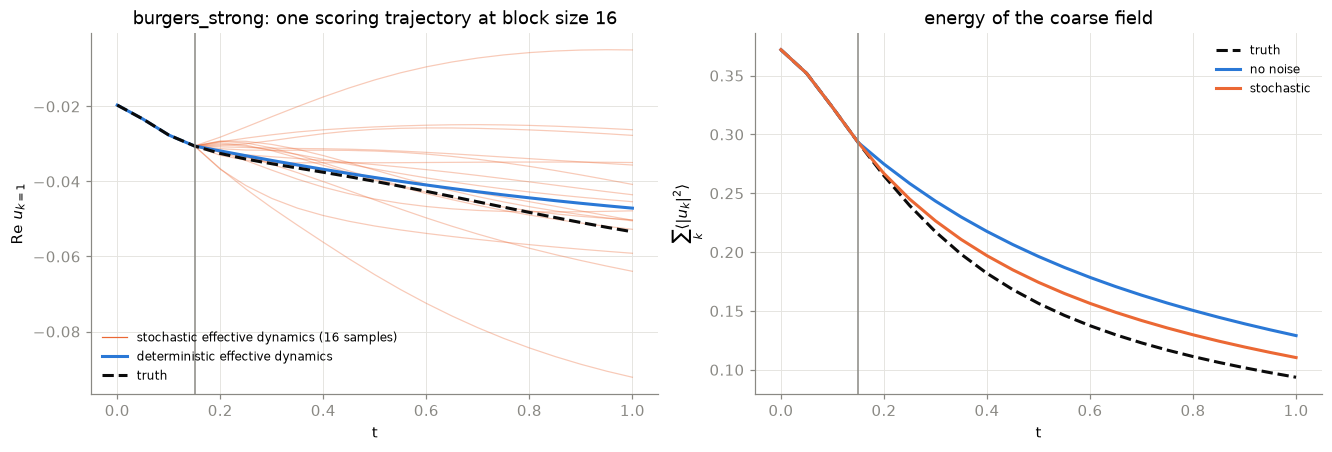

In [ ]:
name = next(t.name for t in TASKS if t.split == "unseen")
env, kernels = envs[name], kernels_of[name]
test = env.u_score[env.levels.predict]
noise, _ = results[name]
h, times = kernels.n_lags, env.dynamics.dt * np.arange(test.values.shape[1])

no_noise = simulate(test, kernels)[0]
ensemble = simulate(test, kernels, noise, n_samples=16, seed=1)
mode = lambda u: np.fft.fft(u, axis=-1, norm="forward")[..., 1].real  # the first Fourier mode of the coarse field

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for sample in ensemble[:, 0]:
    ax0.plot(times, mode(sample), color=SERIES[1], linewidth=0.8, alpha=0.35)
ax0.plot([], [], color=SERIES[1], linewidth=0.8, label="stochastic effective dynamics (16 samples)")
ax0.plot(times, mode(no_noise[0]), color=SERIES[0], label="deterministic effective dynamics")
ax0.plot(times, mode(test.values[0]), color=INK, linestyle="--", label="truth")
ax0.axvline(times[h - 1], color=MUTED, linewidth=1)
ax0.set(xlabel="t", ylabel="Re $u_{k=1}$", title=f"{name}: one scoring trajectory at block size 16")
ax0.legend(fontsize=8)

for color, (label, paths) in zip([INK, SERIES[0], SERIES[1]], [("truth", test.values), ("no noise", no_noise), ("stochastic", ensemble)]):
    ax1.plot(times, spectrum(paths).sum(axis=-1), color=color, linestyle="--" if label == "truth" else "-", label=label)
ax1.axvline(times[h - 1], color=MUTED, linewidth=1)
ax1.set(xlabel="t", ylabel=r"$\sum_k \langle |u_k|^2 \rangle$", title="energy of the coarse field")
ax1.legend(fontsize=8)
plt.show()

## 10. Summary and future directions

**Summary.** The language model reads diagnostics of the data and proposes an operator basis. The Mori-Zwanzig
kernels of that basis are fitted at every scale, their RG flow is extrapolated to a coarser scale, and the result
is fed back: which operators matter there, which do not, what is missing. The same model is post-trained on how
well its proposals did, and the curves of its advantage over greedy measure whether it learned. The final basis gives a closed,
stochastic effective dynamics at the coarse scale: Mori kernels for the drift and, for the noise, its mean given the
initial states plus a stochastic RNN, with all of the randomness drawn at the initial time.
It is checked on data the model never saw.

**What the basis stands for.** The goal is a language model that proposes the *features* of a nearly invariant
subspace of the Mori-Zwanzig dynamics: observables $g = (u, O_1, \dots, O_p)$ whose every step is, as nearly as
possible, a combination of $g$ itself. In this notebook the features are the most specific possible: an explicit
operator basis, whose span is the subspace. In the next version they describe a *family* of operators (degrees,
derivative orders, symmetries), and a search picks the best basis inside it:

| | This notebook | Next version |
|---|---|---|
| The model writes | an explicit list of operators | features of a family of operators |
| The family it defines | exactly one basis | many candidate bases |
| The search inside it | nothing left to choose | picks the best basis (exhaustively when the family is small) |
| The basis is judged on | how well its effective dynamics predicts $u$ | prediction and near-invariance |

An explicit basis is a family with one member, so the next version generalizes this one rather than replacing it; the
hooks for it are in the code with this notebook's behaviour as their defaults (`READERS` and `OBJECTIVES` in
`posttrain.reward`, `Family` in `posttrain.search`). One caveat: the reward here judges the subspace by how well its
effective dynamics predicts $u$ (the prediction error at the coarsest scale), not by how invariant it is. `KernelEnvironment.leak`
measures invariance, but it is not ready to be the reward yet; `03_lessons.ipynb` shows why, along with the lessons
of the runs of this notebook and what the next version still needs.